In [1]:
import pandas as pd

file = pd.read_excel('marine_app_evaluation_finalise.xlsx')

In [2]:
file.columns

Index(['App Name', 'Application Disciplines (AD)',
       'Application Disciplines (AD).1', 'Application Disciplines (AD).2',
       'Application Disciplines (AD).3', 'Application Disciplines (AD).4',
       'Physical Features (P)', 'Physical Features (P).1',
       'Physical Features (P).2', 'Chemical Features (C)',
       'Chemical Features (C).1', 'Biological Features (B)',
       'Biological Features (B).1', 'Biological Features (B).2',
       'Geological Features (G)', 'Geological Features (G).1',
       'Marine Weather (MW)', 'Marine Weather (MW).1',
       'Marine Navigation (NM)', 'Marine Navigation (NM).1',
       'Marine Navigation (NM).2', 'Marine Navigation (NM).3',
       'Social Support (S)', 'Social Support (S).1', 'Social Support (S).2',
       'App Technical Features (A)', 'App Technical Features (A).1',
       'App Technical Features (A).2', 'App Technical Features (A).3',
       'App Technical Features (A).4'],
      dtype='object')

Saved → marine_app_chart.png


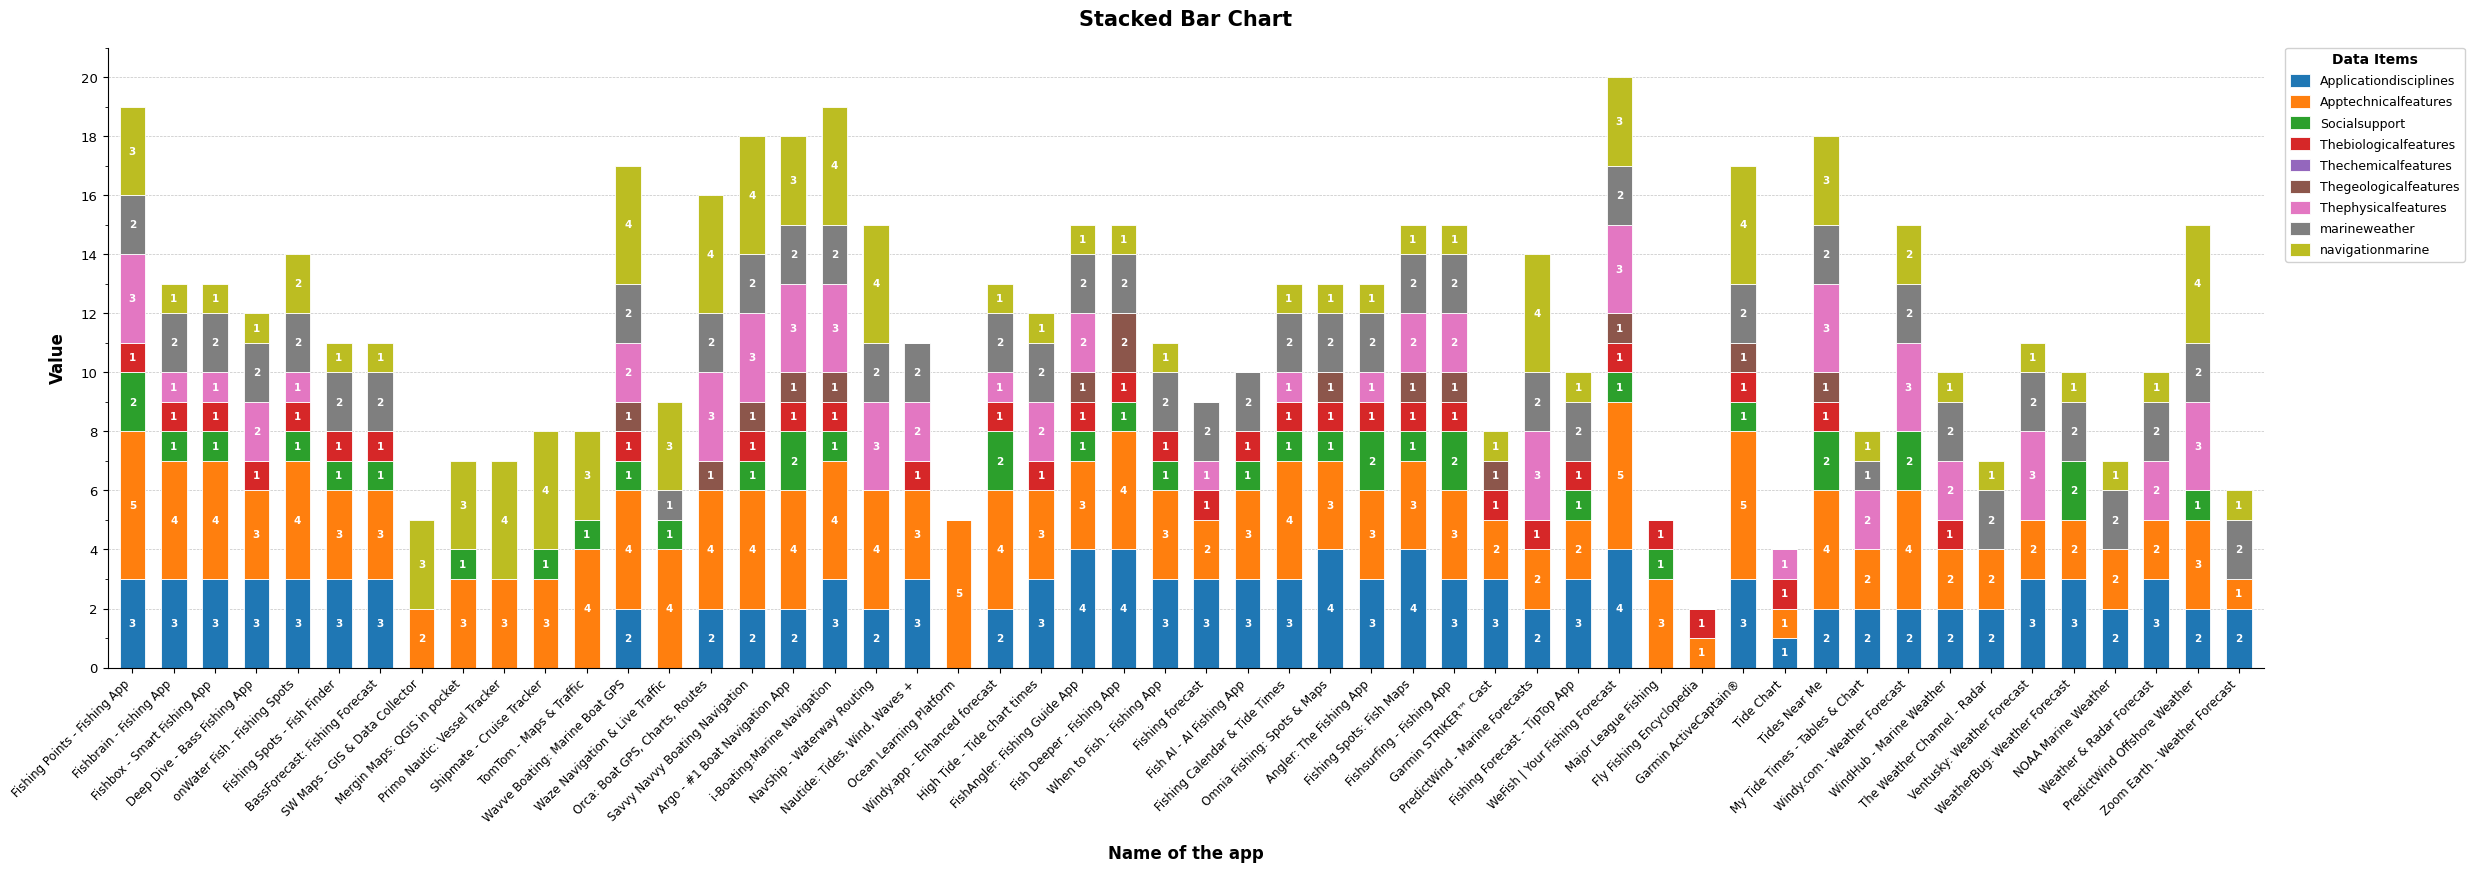

In [4]:
"""
Reproduces the stacked bar chart from marine_app_evaluation_finalise.xlsx.
Usage: python marine_app_chart.py
Requires: pandas, matplotlib, openpyxl
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# ── 1. Load & aggregate ──────────────────────────────────────────────────────

FILE = "marine_app_evaluation_finalise.xlsx"   # change path if needed

df_raw = pd.read_excel(FILE, header=None)

categories = df_raw.iloc[0].ffill().tolist()
data = df_raw.iloc[3:].reset_index(drop=True)
data.columns = range(data.shape[1])
app_names = data[0].tolist()

cat_map = {
    "Applicationdisciplines": "Application Disciplines (AD)",
    "Apptechnicalfeatures":   "App Technical Features (A)",
    "Socialsupport":          "Social Support (S)",
    "Thebiologicalfeatures":  "Biological Features (B)",
    "Thechemicalfeatures":    "Chemical Features (C)",
    "Thegeologicalfeatures":  "Geological Features (G)",
    "Thephysicalfeatures":    "Physical Features (P)",
    "marineweather":          "Marine Weather (MW)",
    "navigationmarine":       "Marine Navigation (NM)",
}

COLORS = {
    "Applicationdisciplines": "#1f77b4",
    "Apptechnicalfeatures":   "#ff7f0e",
    "Socialsupport":          "#2ca02c",
    "Thebiologicalfeatures":  "#d62728",
    "Thechemicalfeatures":    "#9467bd",
    "Thegeologicalfeatures":  "#8c564b",
    "Thephysicalfeatures":    "#e377c2",
    "marineweather":          "#7f7f7f",
    "navigationmarine":       "#bcbd22",
}

result = pd.DataFrame({"App": app_names})
for short, full in cat_map.items():
    col_idx = [i for i, c in enumerate(categories) if c == full and i > 0]
    result[short] = (
        data[col_idx].apply(pd.to_numeric, errors="coerce").sum(axis=1).values
    )
result = result.set_index("App")

# ── 2. Plot ──────────────────────────────────────────────────────────────────

plt.rcParams.update({
    "font.family":      "DejaVu Sans",
    "axes.spines.top":  False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(28, 10))
fig.subplots_adjust(left=0.05, right=0.82, top=0.92, bottom=0.30)

n_bars   = len(result)
bar_w    = 0.62          # narrower bars → more breathing room
x_pos    = np.arange(n_bars)

bottom = np.zeros(n_bars)
bars_handles = {}

for cat in cat_map:
    values = result[cat].values.astype(float)
    bars = ax.bar(
        x_pos, values,
        width=bar_w,
        bottom=bottom,
        color=COLORS[cat],
        label=cat,
        edgecolor="white",
        linewidth=0.6,
    )
    # Value labels — only show when segment is tall enough to fit text
    for idx, (bar, val) in enumerate(zip(bars, values)):
        if val >= 1:
            y_centre = bottom[idx] + val / 2
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                y_centre,
                str(int(val)),
                ha="center", va="center",
                fontsize=7.5, fontweight="bold",
                color="white",
            )
    bottom += values
    bars_handles[cat] = bars[0]

# ── 3. Axes & styling ────────────────────────────────────────────────────────

ax.set_xticks(x_pos)
ax.set_xticklabels(
    result.index,
    rotation=45,
    ha="right",
    fontsize=8.5,
)

ax.set_xlabel("Name of the app", fontsize=12, labelpad=14, fontweight="bold")
ax.set_ylabel("Value",           fontsize=12, labelpad=10, fontweight="bold")
ax.set_title("Stacked Bar Chart", fontsize=15, pad=16, fontweight="bold")

ax.set_xlim(-0.6, n_bars - 0.4)
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.tick_params(axis="y", labelsize=9.5)

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5, color="#888888")
ax.set_axisbelow(True)

# ── 4. Legend ────────────────────────────────────────────────────────────────

legend = ax.legend(
    handles=list(bars_handles.values()),
    labels=list(bars_handles.keys()),
    title="Data Items",
    title_fontsize=10,
    fontsize=9,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    frameon=True,
    framealpha=0.9,
    edgecolor="#cccccc",
    handlelength=1.6,
    handleheight=1.2,
    labelspacing=0.6,
)
legend.get_title().set_fontweight("bold")

plt.savefig("marine_app_chart.png", dpi=180, bbox_inches="tight")
print("Saved → marine_app_chart.png")
plt.show()

In [11]:
"""
Bar chart: number of apps answering each evaluation question.
Usage: python marine_question_chart.py
Requires: pandas, matplotlib, openpyxl
"""

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ── 1. Load data ─────────────────────────────────────────────────────────────

FILE = "marine_app_evaluation_finalise.xlsx"

df_raw = pd.read_excel(FILE, header=None)
codes  = df_raw.iloc[1].tolist()          # AD1, AD2, … A5
data   = df_raw.iloc[3:].reset_index(drop=True)
data.columns = range(data.shape[1])

question_codes = codes[1:]                # drop the "Code" label in col 0
sums = [
    pd.to_numeric(data[i], errors="coerce").sum()
    for i in range(1, len(question_codes) + 1)
]

x      = np.arange(len(question_codes))
labels = question_codes

# ── 2. Plot ──────────────────────────────────────────────────────────────────

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "axes.spines.top":   False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6))
fig.subplots_adjust(left=0.09, right=0.97, top=0.88, bottom=0.20)

ax.bar(x, sums,
       color="#1f77b4",
       width=0.6,
       edgecolor="white",
       linewidth=0.6,
       zorder=3,
       label="Number of apps")

# ── 3. Axes & styling ────────────────────────────────────────────────────────

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8.5)

ax.set_xlabel("Assessment question", fontsize=11, labelpad=12, fontweight="bold")
ax.set_ylabel("Number of apps",      fontsize=11, labelpad=10, fontweight="bold")
ax.set_title(
    "Number of Applications Answering Each Evaluation Question",
    fontsize=12, pad=14, fontweight="bold"
)

ax.tick_params(axis="y", labelsize=9.5)
ax.set_xlim(-0.5, len(x) - 0.5)
ax.set_ylim(0)

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5, color="#888888")
ax.set_axisbelow(True)

ax.legend(fontsize=9, frameon=True, framealpha=0.9,
          edgecolor="#cccccc", loc="upper left",
          bbox_to_anchor=(0.02, 0.98),
          borderpad=1.2)

plt.savefig("marine_question_chart.png", dpi=180, bbox_inches="tight")
print("Saved → marine_question_chart.png")
plt.show()

Saved → marine_question_chart.png


C:\Users\ULTRAPC\AppData\Local\Temp\ipykernel_6372\46671122.py:74: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [6]:
"""
Dual-axis bar chart: Total Downloads (bars, log scale) and Mean Rating (line) by Category.
"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── 1. Load & aggregate ───────────────────────────────────────────────────────

FILE = "final.xlsx"
df = pd.read_excel(FILE)

grouped = (
    df.groupby("Category (Scraped)")
    .agg(mean_stars=("Rating", "mean"),
         total_installs=("Min Installs", "sum"),
         n_apps=("Rating", "count"))
    .reset_index()
    .sort_values("total_installs", ascending=False)  # rank by downloads
    .reset_index(drop=True)
)

categories = grouped["Category (Scraped)"].tolist()
totals     = grouped["total_installs"].values
ratings    = grouped["mean_stars"].values
n          = len(categories)
x          = np.arange(n)

# ── 2. Plot ───────────────────────────────────────────────────────────────────

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "axes.spines.top":   False,
})

fig, ax1 = plt.subplots(figsize=(11, 6.5))

bars = ax1.bar(x, totals, color="#1f4fd1", width=0.55, zorder=3,
               label="Total Downloads")
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(
    lambda v, _: f"{v/1e6:.0f}M" if v >= 1e6 else (f"{v/1e3:.0f}K" if v >= 1e3 else f"{v:.0f}")
))
ax1.set_ylabel("Total Downloads (log scale)", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(categories, rotation=25, ha="right", fontsize=9)
ax1.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.5, zorder=0)

# value labels on bars
for xi, v in zip(x, totals):
    label = f"{v/1e6:.0f}M" if v >= 1e6 else (f"{v/1e3:.0f}K" if v >= 1e3 else f"{v:.0f}")
    ax1.text(xi, v * 1.15, label, ha="center", fontsize=8)

ax2 = ax1.twinx()
ax2.plot(x, ratings, color="#e63946", marker="o", linewidth=2,
         markersize=7, zorder=4, label="Mean Rating")
ax2.set_ylabel("Mean Rating (stars)", fontsize=11, fontweight="bold", color="#e63946")
ax2.set_ylim(3.5, 5)
ax2.tick_params(axis="y", labelcolor="#e63946")

for xi, v in zip(x, ratings):
    ax2.text(xi, v + 0.05, f"{v:.2f}", ha="center", fontsize=8, color="#e63946")

# combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=9, frameon=False)

ax1.set_title("Total Downloads vs. Mean Rating by Category",
              fontsize=13, fontweight="bold", pad=14)

plt.tight_layout()
plt.savefig("marine_dual_axis_chart.png", dpi=180, bbox_inches="tight")
print("Saved → marine_dual_axis_chart.png")

Saved → marine_dual_axis_chart.png


In [2]:
"""
Bubble chart: Classification of applications by category,
number of downloads and user rating.
Each bubble = one category. Size = number of apps. 
X = mean installs (log scale). Y = mean rating.
Usage: python marine_bubble_chart.py
Requires: pandas, matplotlib, openpyxl
"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── 1. Load & aggregate ───────────────────────────────────────────────────────

FILE = "final.xlsx"

df = pd.read_excel(FILE)

grouped = (
    df.groupby("Category (Scraped)")
    .agg(
        mean_rating  = ("Rating",       "mean"),
        mean_installs= ("Min Installs", "mean"),
        n_apps       = ("App Name",     "count"),
    )
    .reset_index()
    .sort_values("Category (Scraped)")
    .reset_index(drop=True)
)

# ── 2. Style ──────────────────────────────────────────────────────────────────

COLORS = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728",
    "#9467bd", "#8c564b", "#e377c2",
]

plt.rcParams.update({
    "font.family":        "DejaVu Sans",
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.grid":          True,
    "grid.linestyle":     "--",
    "grid.linewidth":     0.5,
    "grid.alpha":         0.5,
    "grid.color":         "#aaaaaa",
})

# ── 3. Plot ───────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 7))
fig.subplots_adjust(left=0.10, right=0.78, top=0.88, bottom=0.12)

# Scale bubble area proportional to number of apps
area_scale = 120
sizes = grouped["n_apps"] * area_scale

scatter_handles = []
for i, row in grouped.iterrows():
    sc = ax.scatter(
        row["mean_installs"],
        row["mean_rating"],
        s=row["n_apps"] * area_scale,
        color=COLORS[i % len(COLORS)],
        alpha=0.80,
        edgecolors="white",
        linewidths=1.5,
        zorder=3,
        label=row["Category (Scraped)"],
    )
    scatter_handles.append(sc)
    # Label each bubble with app count
    ax.text(
        row["mean_installs"],
        row["mean_rating"] + 0.008,
        f'n={int(row["n_apps"])}',
        ha="center", va="bottom",
        fontsize=8.5, color="#333333",
    )

# ── 4. Axes ───────────────────────────────────────────────────────────────────

ax.set_xscale("log")
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
ax.tick_params(axis="x", labelsize=8.5, rotation=20)
ax.tick_params(axis="y", labelsize=9)

ax.set_xlabel("Mean Number of Downloads (log scale)",
              fontsize=11, labelpad=10, fontweight="bold")
ax.set_ylabel("Mean User Rating (Stars)",
              fontsize=11, labelpad=10, fontweight="bold")
ax.set_title(
    "Classification of Applications by Category,\nNumber of Downloads and User Rating",
    fontsize=13, pad=14, fontweight="bold", linespacing=1.5,
)

# Y axis range
ax.set_ylim(4.0, 4.85)
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))

# ── 5. Legend ─────────────────────────────────────────────────────────────────

# Category colour legend
cat_legend = ax.legend(
    handles=[
        plt.Line2D([0], [0], marker="o", color="w",
                   markerfacecolor=COLORS[i], markersize=10,
                   label=row["Category (Scraped)"])
        for i, (_, row) in enumerate(grouped.iterrows())
    ],
    title="Category",
    title_fontsize=9,
    fontsize=8.5,
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    borderaxespad=0,
    frameon=True,
    framealpha=0.9,
    edgecolor="#cccccc",
)
cat_legend.get_title().set_fontweight("bold")
ax.add_artist(cat_legend)

# Bubble size legend
for n_apps, label in [(2, "2 apps"), (10, "10 apps"), (18, "18 apps")]:
    ax.scatter([], [], s=n_apps * area_scale,
               color="#aaaaaa", alpha=0.7, edgecolors="white",
               linewidths=1.2, label=label)

size_legend = ax.legend(
    title="Number of apps\n(bubble size)",
    title_fontsize=9,
    fontsize=8.5,
    loc="lower left",
    bbox_to_anchor=(1.01, 0.0),
    borderaxespad=0,
    frameon=True,
    framealpha=0.9,
    edgecolor="#cccccc",
)
size_legend.get_title().set_fontweight("bold")

plt.savefig("marine_bubble_chart.png", dpi=180, bbox_inches="tight")
print("Saved → marine_bubble_chart.png")

Saved → marine_bubble_chart.png


In [1]:
"""
Scatter plot with linear regression line.
Y axis: log10 scale to handle the outlier.
"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats

# ── 1. Load & prepare ─────────────────────────────────────────────────────────

FILE = "final.xlsx"
df   = pd.read_excel(FILE).reset_index(drop=True)

total_installs  = df["Min Installs"].sum()
df["total_pct"] = df["Min Installs"] / total_installs * 100

x      = df["Rating"].values
y      = df["total_pct"].values
labels = [f"A{i+1}" for i in range(len(df))]

# ── 2. Regression in log space ────────────────────────────────────────────────

log_y = np.log10(y)
slope, intercept, r_value, _, _ = stats.linregress(x, log_y)
r2 = r_value ** 2

x_line = np.linspace(x.min() - 0.05, x.max() + 0.05, 300)
y_line = 10 ** (slope * x_line + intercept)

# ── 3. Plot ───────────────────────────────────────────────────────────────────

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "axes.spines.top":   False,
    "axes.spines.right": False,
})

colors = [
    plt.cm.tab20(i % 20) if i < 40 else plt.cm.tab20b(i % 20)
    for i in range(len(df))
]

fig, ax = plt.subplots(figsize=(11, 7))
fig.subplots_adjust(left=0.11, right=0.97, top=0.91, bottom=0.10)

for i in range(len(df)):
    ax.scatter(x[i], y[i], color=colors[i], s=120,
               edgecolors="white", linewidths=0.6, zorder=3)
    ax.text(x[i] + 0.005, y[i] * 1.12, labels[i],
            fontsize=6.5, color="#222222", zorder=4)

ax.plot(x_line, y_line, color="red", linewidth=1.8, zorder=2)

ax.text(0.08, 0.95, f"R2 = {r2:.2f}",
        transform=ax.transAxes, fontsize=11, ha="left", va="top")

# ── 4. Log Y axis with clean ticks ───────────────────────────────────────────

ax.set_yscale("log")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(
    lambda val, _: f"{val:g}"
))

# Manually set readable tick positions
ax.set_yticks([0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100])
ax.set_ylim(y.min() * 0.5, y.max() * 2)

ax.tick_params(axis="both", labelsize=9)
ax.set_xlim(x.min() - 0.15, x.max() + 0.15)

ax.set_xlabel("Number of Stars",        fontsize=11, labelpad=8,  fontweight="bold")
ax.set_ylabel("Share of total installs (%)  [log scale]", fontsize=11, labelpad=8,  fontweight="bold")
ax.set_title("Scatter Plot with Linear Regression Line",
             fontsize=13, pad=14, fontweight="bold")

ax.grid(axis="both", linestyle="--", linewidth=0.4, alpha=0.5, color="#aaaaaa")
ax.set_axisbelow(True)

plt.savefig("marine_scatter_chart.png", dpi=180, bbox_inches="tight")
print("Saved → marine_scatter_chart.png")

Saved → marine_scatter_chart.png


In [21]:
"""
SPSS-style Pearson correlation table as PNG.
"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy import stats

# ── 1. Compute ────────────────────────────────────────────────────────────────

df          = pd.read_excel("final.xlsx").reset_index(drop=True)
total       = df["Min Installs"].sum()
df["Total"] = df["Min Installs"] / total * 100
r, p        = stats.pearsonr(df["Rating"].values, df["Total"].values)
n           = len(df)
sig         = "*" if p < 0.05 else ""

def fmt(v):
    """SPSS style: leading comma for decimals, no leading zero."""
    s = f"{abs(v):.3f}"[1:]          # strip leading "0" → ".038"
    s = s.replace(".", ",")          # "," as decimal separator
    return ("-" + s) if v < 0 else s

r_str = fmt(r) + sig
p_str = fmt(p)

# ── 2. Table data ─────────────────────────────────────────────────────────────

# Each entry: (col0, col1, col2-Numberofstars, col3-Total)
rows = [
    ("Numberofstars", "Corrélation de Pearson", "1",    r_str),
    ("",              "Sig. (bilatérale)",       "",     p_str),
    ("",              "N",                       str(n), str(n)),
    ("Total",         "Corrélation de Pearson",  r_str,  "1"),
    ("",              "Sig. (bilatérale)",        p_str,  ""),
    ("",              "N",                        str(n), str(n)),
]

col_headers = ["", "", "Numberofstars", "Total"]

# ── 3. Draw ───────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

# -- layout constants (in data coords 0-10) --
left, right = 0.3, 9.7
col_x = [left, 2.8, 7.0, 8.6]     # left edge of each column
col_w = [2.5,  4.2, 1.6, 1.4]
header_top  = 9.2
header_bot  = 8.4
row_h       = 0.85
data_top    = header_bot
table_bot   = data_top - len(rows) * row_h

def hline(y, x0=left, x1=right, lw=0.8):
    ax.plot([x0, x1], [y, y], color="black", linewidth=lw,
            transform=ax.transData, clip_on=False)

def vline(x, y0, y1, lw=0.8):
    ax.plot([x, x], [y0, y1], color="black", linewidth=lw,
            transform=ax.transData, clip_on=False)

# Title
ax.text(5, 9.7, "Corrélations", ha="center", va="top",
        fontsize=11, fontweight="bold")

# Header borders
hline(header_top, lw=1.2)
hline(header_bot, lw=0.8)

# Column headers
for ci in range(2, 4):
    cx   = col_x[ci]
    mid  = cx + col_w[ci] / 2
    # Two-line header like SPSS ("Numberofstar" + "s")
    label = col_headers[ci]
    if label == "Numberofstars":
        ax.text(mid, (header_top + header_bot) / 2 + 0.12,
                "Numberofstar", ha="center", va="center", fontsize=8.5)
        ax.text(mid, (header_top + header_bot) / 2 - 0.25,
                "s",            ha="center", va="center", fontsize=8.5)
    else:
        ax.text(mid, (header_top + header_bot) / 2,
                label, ha="center", va="center", fontsize=8.5)

# Data rows
for ri, row in enumerate(rows):
    y_top = data_top - ri * row_h
    y_mid = y_top - row_h / 2

    for ci, cell in enumerate(row):
        cx  = col_x[ci]
        cw  = col_w[ci]
        pad = 0.12
        if ci <= 1:
            ax.text(cx + pad, y_mid, cell,
                    ha="left", va="center", fontsize=8.5)
        else:
            ax.text(cx + cw / 2, y_mid, cell,
                    ha="center", va="center", fontsize=8.5)

    # Bottom border after each group of 3 rows
    if ri in (2, 5):
        hline(y_top - row_h, lw=0.8)

# Outer box
hline(header_top, lw=1.2)
hline(table_bot,  lw=1.2)
vline(left,  table_bot, header_top, lw=1.0)
vline(right, table_bot, header_top, lw=1.0)

# Footnote
fn_text = f"*. La corrélation est significative au niveau 0.05 (bilatéral)."
ax.text(left, table_bot - 0.25, fn_text,
        ha="left", va="top", fontsize=7.5, style="italic")

plt.tight_layout()
plt.savefig("marine_correlation_table.png", dpi=180, bbox_inches="tight")
print("Saved → marine_correlation_table.png")

Saved → marine_correlation_table.png


In [1]:
"""
Scatter plot with manually-positioned, non-overlapping labels.
"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

FILE = "final.xlsx"

df = pd.read_excel(FILE).reset_index(drop=True)
grouped = (
    df.groupby("Category (Scraped)")
    .agg(mean_rating=("Rating", "mean"),
         mean_installs=("Min Installs", "mean"))
    .reset_index()
    .sort_values("mean_rating")
    .reset_index(drop=True)
)

x      = grouped["mean_rating"].values
y      = grouped["mean_installs"].values
labels = grouped["Category (Scraped)"].tolist()

# Manual offsets per category: (dx, dy) in axis-fraction-like units, tune as needed
# Format: "Category Name": (x_offset, y_offset)
offsets = {
    "Maps & Navigation": (0.02, 0.10),
    "Sports":            (0.02, -0.10),
    "Travel & Local":    (0.02, 0.10),
    "Weather":           (0.02, -0.12),
    "Social":            (-0.15, 0.10),
    "Productivity":      (0.02, 0.10),
    "Education":         (0.02, -0.10),
}

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "axes.spines.top":   False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(left=0.13, right=0.88, top=0.88, bottom=0.12)

ax.scatter(x, y, color="#1f77b4", s=110, edgecolors="white",
           linewidths=1.2, zorder=4)

y_range = y.max() - y.min()
x_range = x.max() - x.min()

for xi, yi, label in zip(x, y, labels):
    dx, dy = offsets.get(label, (0.02, 0.08))
    tx = xi + dx * x_range
    ty = yi + dy * y_range
    ax.annotate(
        label,
        xy=(xi, yi), xycoords="data",
        xytext=(tx, ty), textcoords="data",
        fontsize=8.5, zorder=5,
        bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="#888888", lw=0.6),
        arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6,
                         shrinkA=2, shrinkB=8),
    )

ax.set_xlabel("Rating average",    fontsize=10, labelpad=8,  fontweight="bold")
ax.set_ylabel("Downloads", fontsize=10, labelpad=8,  fontweight="bold")
ax.set_title("Downloads vs. Rating Average by App Category",
             fontsize=12, pad=14, fontweight="bold", loc="left")

ax.yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f}")
)
ax.text(0.0, 1.01, "1e6", transform=ax.transAxes, fontsize=8.5, va="bottom")

ax.tick_params(axis="both", labelsize=9)
ax.set_xlim(x.min() - 0.25, x.max() + 0.30)
ax.set_ylim(-y.max() * 0.10, y.max() * 1.30)

ax.grid(axis="both", linestyle="--", linewidth=0.4, alpha=0.5, color="#aaaaaa")
ax.set_axisbelow(True)

plt.savefig("marine_scatter_chart.png", dpi=180, bbox_inches="tight")
print("Saved → marine_scatter_chart.png")

Saved → marine_scatter_chart.png


In [ ]:
"""
Reads final.xlsx and plots the number of apps per category.

Usage:
    python apps_per_category.py

Requires: pandas, matplotlib, openpyxl
    pip install pandas matplotlib openpyxl
"""

import pandas as pd
import matplotlib.pyplot as plt

# --- Config ---
INPUT_FILE = "final.xlsx"
SHEET_NAME = "Results"
CATEGORY_COLUMN = "Category"
OUTPUT_IMAGE = "apps_per_category.png"

# --- Read data ---
df = pd.read_excel(INPUT_FILE, sheet_name=SHEET_NAME)

# --- Count apps per category ---
counts = df[CATEGORY_COLUMN].value_counts().sort_values(ascending=False)

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(counts.index, counts.values, color="#4C72B0")

# Add count labels above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_title("Number of Apps per Category", fontsize=14, fontweight="bold")
ax.set_xlabel("Category")
ax.set_ylabel("Number of Apps")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# --- Save and show ---
plt.savefig(OUTPUT_IMAGE, dpi=200)
print(f"Saved chart to {OUTPUT_IMAGE}")
plt.show()